**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 2**
Pandas para el análisis de datos en Python

---

*   NOMBRE: Adolfo Siliceo Vásquez
*   MATRÍCULA: A01841467


---

En esta actividad trabajarás con el archivo `cleaned_weather.csv`, un extracto del conjunto de datos meteorológicos a lo largo de todo el año 2020 en una estación del Instituto *Max Planck* (Alemania) disponible en Kaggle.

Los datos meteorológicos fueron registrados cada 10 minutos e incluyen los siguientes indicadores:

*   `timestamp`: Fecha y hora de la observación.
*   `p`: Presión atmosférica en milibares (mbar)
*   `T`: Temperatura del aire en grados Celsius (°C)
*   `Tpot`: Temperatura potencial en Kelvin (K)
*   `rh`: Humedad relativa en porcentaje (%)
*   `VPact`: Presión real de vapor en milibares (mbar)
*   `sh`: Humedad específica en gramos por kilogramo (g/kg)
*   `H2OC`: Concentración de vapor de agua en milimoles por mol (mmol/mol) de aire seco
*   `rho`: Densidad del aire en gramos por metro cúbico (g/m³)
*   `wv`: Velocidad del viento en metros por segundo (m/s)
*   `wd`: Dirección del viento en grados (°)
*   `rain`: Precipitación total en milímetros (mm)
*   `raining`: Duración de la lluvia en segundos (s)

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.


In [234]:
import pandas as pd
import matplotlib.pyplot as plt

1.	Descarga el archivo: `cleaned_weather.csv` y guarda, en un dataframe (`weather_df`), todos sus registros.
- Determina la dimensionalidad del dataframe y obtén los identificadores de columnas.
- Renombra las columnas para facilitar la interpretación de los indicadores en los ejercicios siguientes:
  - `medicion, presion_atmosferica, temperatura_celsius, temperatura_kelvin, humedad_relativa, presion_vapor, humedad_especifica, concentracion_vapor, densidad_aire, velocidad_viento, direccion_viento, precipitacion_total, duracion_lluvia`
- Muestra los primeros y los últimos 5 registros.
- ¿Hay valores faltantes en el dataframe?





In [235]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [236]:
weather_df = pd.read_csv('/content/drive/MyDrive/Ciencia Analitica de Datos/Semana2/Tarea_semana2/cleaned_weather.csv')




In [237]:
weather_df.shape

(52696, 13)

Con la instrucción **shape** obtenemos el numero de registros  del dataframe y el numero de columnas

In [238]:
weather_df.columns

Index(['timestamp', 'p', 'T', 'Tpot', 'rh', 'VPact', 'sh', 'H2OC', 'rho', 'wv',
       'wd', 'rain', 'raining'],
      dtype='object')

con .columns vemos loos identificadores de las columnas de nuestro dataframe

In [239]:
weather_df.columns = ['medicion', 'presion_atmosferica',
                      'temperatura_celsius',
                      'temperatura_kelvin',
                      'humedad_relativa',
                      'presion_vapor',
                      'humedad_especifica',
                      'concentracion_vapor',
                      'densidad_aire',
                      'velocidad_viento',
                      'direccion_viento',
                      'precipitacion_total',
                      'duracion_lluvia']

In [240]:
weather_df.head(5)

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
0,01/01/20 0:10,1008.89,0.71,273.18,86.1,5.54,3.42,5.49,1280.62,1.02,224.3,0.0,0
1,01/01/20 0:20,1008.76,0.75,273.22,85.2,5.49,3.39,5.45,1280.33,0.43,206.8,0.0,0
2,01/01/20 0:30,1008.66,0.73,273.21,85.1,5.48,3.39,5.43,1280.29,0.61,197.1,0.0,0
3,01/01/20 0:40,1008.64,0.37,272.86,86.3,5.41,3.35,5.37,1281.97,1.11,206.4,0.0,0
4,01/01/20 0:50,1008.61,0.33,272.82,87.4,5.47,3.38,5.42,1282.08,0.49,209.6,0.0,0


In [241]:
weather_df.tail(5)

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
52691,31/12/20 23:20,978.32,2.28,277.16,80.0,5.76,3.67,5.89,1234.61,0.73,180.6,0.0,0
52692,31/12/20 23:30,978.30,2.13,277.01,83.1,5.92,3.77,6.05,1235.20,0.43,174.0,0.0,0
52693,31/12/20 23:40,978.26,1.99,276.88,82.2,5.80,3.69,5.93,1235.82,0.38,248.9,0.0,0
52694,31/12/20 23:50,978.26,2.07,276.95,81.4,5.77,3.68,5.90,1235.49,0.57,196.6,0.0,0
52695,01/01/21 0:00,978.24,2.01,276.89,82.4,5.82,3.71,5.95,1235.71,0.57,221.3,0.0,0


In [242]:
weather_df.isna().sum()

,0
medicion,0
presion_atmosferica,0
temperatura_celsius,0
temperatura_kelvin,0
humedad_relativa,0
presion_vapor,0
humedad_especifica,0
concentracion_vapor,0
densidad_aire,0
velocidad_viento,0


con la instrucción isna() se buscan los valores faltantes o nulos y se convierten a TRUE y .sum sumaría la cantidad de valores que faltan en cada columna, al ser todos ceros  vemos que no hay valores faltantes.

2. Determina el tipo de datos que tienen las columnas.
- Cambia la columna `medicion` a datetime utilizando el formato: `%d/%m/%y %H:%M`
- Obtén dos columnas adicionales separando `medicion` en `fecha` y `hora`

In [243]:
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52696 entries, 0 to 52695
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   medicion             52696 non-null  object 
 1   presion_atmosferica  52696 non-null  float64
 2   temperatura_celsius  52696 non-null  float64
 3   temperatura_kelvin   52696 non-null  float64
 4   humedad_relativa     52696 non-null  float64
 5   presion_vapor        52696 non-null  float64
 6   humedad_especifica   52696 non-null  float64
 7   concentracion_vapor  52696 non-null  float64
 8   densidad_aire        52696 non-null  float64
 9   velocidad_viento     52696 non-null  float64
 10  direccion_viento     52696 non-null  float64
 11  precipitacion_total  52696 non-null  float64
 12  duracion_lluvia      52696 non-null  int64  
dtypes: float64(11), int64(1), object(1)
memory usage: 5.2+ MB


con la instrucción anterior vemos en la columna Dtype el tipo de datos de cada columna.

In [244]:
weather_df['medicion'] = pd.to_datetime(weather_df['medicion'], format='%d/%m/%y %H:%M')
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52696 entries, 0 to 52695
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   medicion             52696 non-null  datetime64[ns]
 1   presion_atmosferica  52696 non-null  float64       
 2   temperatura_celsius  52696 non-null  float64       
 3   temperatura_kelvin   52696 non-null  float64       
 4   humedad_relativa     52696 non-null  float64       
 5   presion_vapor        52696 non-null  float64       
 6   humedad_especifica   52696 non-null  float64       
 7   concentracion_vapor  52696 non-null  float64       
 8   densidad_aire        52696 non-null  float64       
 9   velocidad_viento     52696 non-null  float64       
 10  direccion_viento     52696 non-null  float64       
 11  precipitacion_total  52696 non-null  float64       
 12  duracion_lluvia      52696 non-null  int64         
dtypes: datetime64[ns](1), float64(1

se realiza el cambio del formato de la columna medición y comprobamos el cambio con .info()

In [245]:
weather_df['fecha'] = weather_df['medicion'].dt.date
weather_df['hora'] = weather_df['medicion'].dt.time

weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52696 entries, 0 to 52695
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   medicion             52696 non-null  datetime64[ns]
 1   presion_atmosferica  52696 non-null  float64       
 2   temperatura_celsius  52696 non-null  float64       
 3   temperatura_kelvin   52696 non-null  float64       
 4   humedad_relativa     52696 non-null  float64       
 5   presion_vapor        52696 non-null  float64       
 6   humedad_especifica   52696 non-null  float64       
 7   concentracion_vapor  52696 non-null  float64       
 8   densidad_aire        52696 non-null  float64       
 9   velocidad_viento     52696 non-null  float64       
 10  direccion_viento     52696 non-null  float64       
 11  precipitacion_total  52696 non-null  float64       
 12  duracion_lluvia      52696 non-null  int64         
 13  fecha                52696 non-

creamos dos columnas y las mostramos con .info()

3. Determina la cantidad de valores únicos de cada columna.
- La columna `medicion` tiene un valor menos que el número total de filas del dataframe, lo que indica que hay una fecha duplicada. Identifica cuál es.
- Comprueba si las demás columnas también contienen los mismos valores; si es así, elimina  uno de los registros duplicados.


In [246]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [247]:
weather_df[weather_df.duplicated(subset=['medicion'], keep=False)]

,medicion,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia,fecha,hora
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,96.2,5.24,3.29,5.28,1269.29,1.04,215.4,0.0,0,2020-05-12,06:00:00


In [248]:
weather_df.duplicated().sum()
weather_df = weather_df.drop_duplicates()
weather_df.shape



(52695, 15)

como se muestra en el punto anterior, las dos líneas son completamente iguales, por lo que se elimina una de ellas, quedando 52695 registros en el dataframe

4. Imprime nuevamente las cantidad de valores únicos por columna.
- ¿Por qué son 144 horas diferentes?
- La cantidad de combinaciones únicas de fecha y hora no coincide con el número total de mediciones. Aunque no haya valores NaN, esto no garantiza que no se hayan omitido registros. Identifica las fechas en las que faltan mediciones.
- Una vez concluido el análisis de mediciones faltantes, elimina todos los registros que no correspondan al año 2020 y la columna `medicion`.


In [249]:
weather_df.nunique()

,0
medicion,52695
presion_atmosferica,5052
temperatura_celsius,3680
temperatura_kelvin,3836
humedad_relativa,5494
presion_vapor,2059
humedad_especifica,1337
concentracion_vapor,2087
densidad_aire,14826
velocidad_viento,977


In [250]:
weather_df['hora'].groupby(weather_df['hora']).count().sort_values(ascending=False)

,hora
hora,
00:00:00,366
00:10:00,366
00:20:00,366
00:30:00,366
00:40:00,366
...,...
09:50:00,365
10:00:00,365
10:10:00,365


**¿Por qué son 144 horas diferentes?**
si hacemos un group by por el campo hora como en la instrucción anterior, hacemos el conteo y lo ordenamos, vemos que hay 144 grupos (144 rows) de horas unicas. esto es porque se hicieron muestreos cada 10 minutos. Si cada hora se tomaron 6 muestras, en 24 horas ... 6x24 darían 144 grupos de horas únicas.


In [251]:
weather_df['fecha'].groupby(weather_df['fecha']).count().sort_values(ascending=True).head(5)

,fecha
fecha,
2021-01-01,1
2020-05-29,135
2020-01-01,143
2020-12-19,144
2020-12-18,144


los días en los que faltan mediciones  son :  2021-01-01 , 2020-05-29 y 2020-01-01

como se aprecia arriba, 144 es el total de mediciones que hay por día, cuando hay un numero menor a ese es cuando faltan mediciones.

In [252]:
weather_df = weather_df[weather_df.medicion.dt.year == 2020].drop(columns=['medicion'])
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52694 entries, 0 to 52694
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   presion_atmosferica  52694 non-null  float64
 1   temperatura_celsius  52694 non-null  float64
 2   temperatura_kelvin   52694 non-null  float64
 3   humedad_relativa     52694 non-null  float64
 4   presion_vapor        52694 non-null  float64
 5   humedad_especifica   52694 non-null  float64
 6   concentracion_vapor  52694 non-null  float64
 7   densidad_aire        52694 non-null  float64
 8   velocidad_viento     52694 non-null  float64
 9   direccion_viento     52694 non-null  float64
 10  precipitacion_total  52694 non-null  float64
 11  duracion_lluvia      52694 non-null  int64  
 12  fecha                52694 non-null  object 
 13  hora                 52694 non-null  object 
dtypes: float64(11), int64(1), object(2)
memory usage: 6.0+ MB


5. Obtén un dataframe `indicadores_diarios` que sólo almacene el mayor valor de las mediciones por fecha para responder:
- ¿Cuál fue la máxima precipitación y a qué fecha pertenece?
- ¿Cuáles fueron los tres días con las velocidades de viento más altas registradas?
- ¿Cuántos días rebasaron el 90% de humedad relativa y los 30° celsius?

In [253]:
indicadores_diarios = weather_df.groupby('fecha').max(numeric_only=True)
indicadores_diarios.head()

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
fecha,,,,,,,,,,,,
2020-01-01,1008.89,4.58,277.27,95.0,5.81,3.60,5.77,1298.02,1.91,356.9,0.0,0
2020-01-02,1004.16,6.47,279.72,93.9,5.57,3.48,5.58,1304.37,2.67,358.8,0.0,0
2020-01-03,998.45,8.17,281.80,89.3,9.34,5.86,9.39,1266.97,8.79,336.5,0.2,470
2020-01-04,1003.47,6.61,280.15,91.4,8.54,5.36,8.58,1270.10,4.61,354.7,1.0,600
2020-01-05,1009.07,4.43,277.01,85.3,6.44,3.99,6.40,1275.47,3.14,274.6,0.0,0


In [254]:
(indicadores_diarios.sort_values(by='precipitacion_total', ascending=False).drop(columns=['presion_atmosferica','temperatura_celsius','temperatura_kelvin',
                                                                                          'humedad_relativa','presion_vapor','humedad_especifica',
                                                                                          'concentracion_vapor','densidad_aire','velocidad_viento',
                                                                                          'direccion_viento','duracion_lluvia'])).head(1)

,precipitacion_total
fecha,
2020-06-16,11.2


In [255]:
(indicadores_diarios.sort_values(by='velocidad_viento', ascending=False).drop(columns=['presion_atmosferica','temperatura_celsius','temperatura_kelvin',
                                                                                          'humedad_relativa','presion_vapor','humedad_especifica',
                                                                                          'concentracion_vapor','densidad_aire','precipitacion_total',
                                                                                          'direccion_viento','duracion_lluvia'])).head(3)

,velocidad_viento
fecha,
2020-02-10,13.77
2020-02-16,13.00
2020-02-09,12.52


In [256]:
indicadores_diarios.query("humedad_relativa > 90 and temperatura_celsius > 30").drop(columns=['presion_atmosferica','temperatura_kelvin',
                                                                                          'presion_vapor','humedad_especifica',
                                                                                          'concentracion_vapor','densidad_aire',
                                                                                              'precipitacion_total','velocidad_viento',
                                                                                          'direccion_viento','duracion_lluvia'])

,temperatura_celsius,humedad_relativa
fecha,,
2020-08-11,31.42,93.8
2020-08-12,32.26,94.4
2020-08-20,30.38,97.1
2020-08-21,34.56,94.7
2020-09-15,30.16,99.9


In [257]:
len(indicadores_diarios.query("humedad_relativa > 90 and temperatura_celsius > 30"))

5

la respuesta a este punto son 5 días en los que se cumplen las dos condiciones de humedad y temperatura.



Silvia Te Explica. (s.f). *Función QUERY de PANDAS (PYTHON) en 5 MINUTOS*. [Video]. Youtube. https://www.youtube.com/watch?v=GSa-PTb2L7Q

6. La función `describe()` resume múltiples estadísticas descriptivas. Utiliza esta función para explorar y responder las preguntas sobre las variables en el dataframe de `indicadores_diarios `:
- ¿Cuál es la desviación estándar de la concentración de vapor y qué indica?
- ¿Cuál es la mediana de la presión atmosférica y qué significa?
- ¿Cuál es el tercer cuartil de la duración de la lluvia y cómo se interpreta?

In [258]:
indicadores_diarios.describe()

,presion_atmosferica,temperatura_celsius,temperatura_kelvin,humedad_relativa,presion_vapor,humedad_especifica,concentracion_vapor,densidad_aire,velocidad_viento,direccion_viento,precipitacion_total,duracion_lluvia
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,992.977842,15.343770,289.431667,90.886530,11.409454,7.214016,11.539180,1232.622814,5.245164,317.673689,0.314208,240.382514
std,8.543447,7.850339,7.942175,9.201588,4.507555,2.872647,4.573267,32.702446,2.097012,50.611324,0.979721,273.840002
min,959.900000,-0.120000,273.460000,55.440000,3.320000,2.050000,3.290000,1167.050000,1.570000,69.570000,0.000000,0.000000
25%,988.015000,8.840000,282.732500,85.400000,7.647500,4.832500,7.742500,1207.590000,3.662500,279.075000,0.000000,0.000000
50%,993.300000,15.060000,289.160000,93.250000,10.715000,6.705000,10.735000,1231.455000,4.880000,346.650000,0.000000,0.000000
75%,998.432500,21.695000,295.957500,99.900000,14.462500,9.180000,14.685000,1256.057500,6.495000,357.300000,0.200000,600.000000
max,1020.070000,34.800000,309.130000,100.000000,24.160000,15.400000,24.530000,1318.520000,13.770000,360.000000,11.200000,600.000000


In [259]:
indicadores_diarios['concentracion_vapor'].describe()[['std']]

,concentracion_vapor
std,4.573267


La desviacion estandar de la concentración de vapor es de 4.576325 y indica que tantas unidades de alejan las mediciones de su valor promedio central

Dr. Xabi. (s.f). *Como Realizar un Resumen Estadístico con .describe() en Python (Google Colab)* [Video]. https://www.youtube.com/watch?v=M4SajbGrgsk

In [260]:
indicadores_diarios['presion_atmosferica'].describe()[['50%']]

,presion_atmosferica
50%,993.3


la mediana de la presion atmosférica es de 993.3, significa que al ordenar los datos de presion atmosférica de menor a mayor, 993.3 es el punto central de la lista, por debajo de esta se encuentra el 50% y por arriba de esta se encuentra el otro 50%

In [261]:
indicadores_diarios['duracion_lluvia'].describe()[['75%']]

,duracion_lluvia
75%,600.0


el tercer cuartil de la duración de lluvia es de 600, de la lista de mediciones de la duración de lluvia ordenada de menor a mayor,  600 indica que por debajo de este se encuentran el 75% de los registros y por arriba del 600  queda el 25% de los registros. si se expresa en minutos nos indicaría que el 75% de las mediciones fueron menor a 600 minutos y el 25% de las mediciones fueron mayores a 600 minutos.

7.	Dibuja un histograma para cada una de las columnas de `indicadores_diarios`.

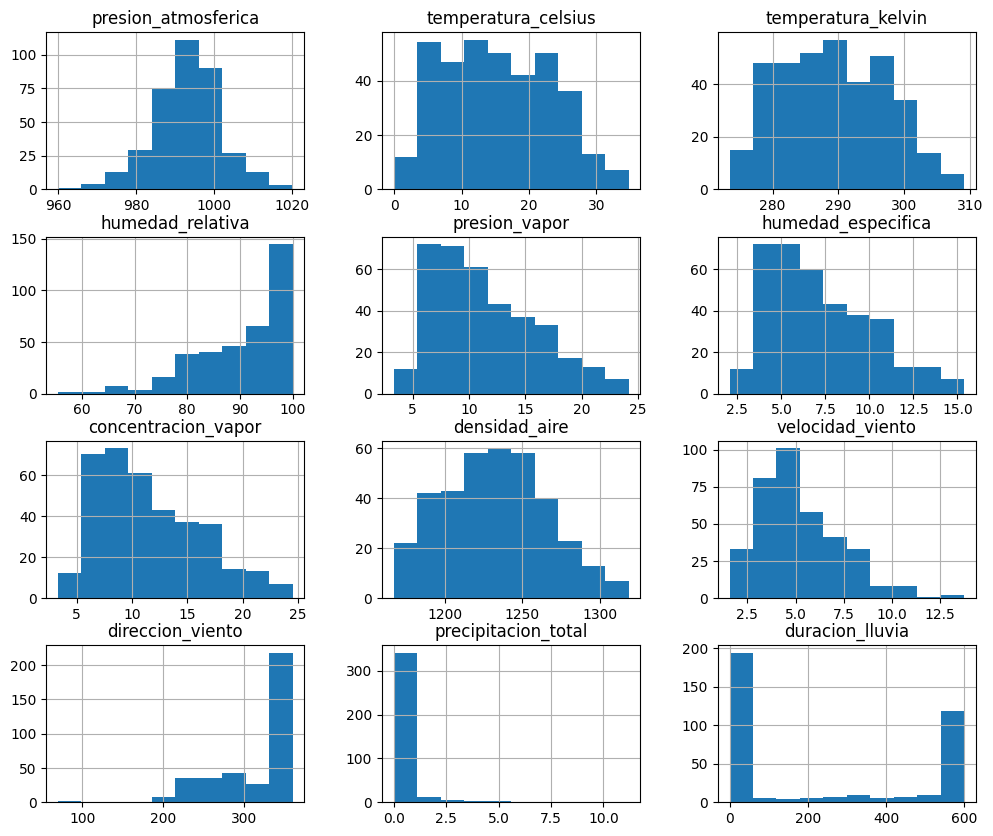

In [262]:
indicadores_diarios.hist(figsize=(12,10))
plt.show()

8. Utiliza el dataframe de indicadores diarios para crear un nuevo dataframe `indicadores_mensuales`. Para ello:
- Crea una nueva columna `mes` a partir de la fecha que se encuentra en el índice.
- Haciendo uso de `groupby()`, calcula los promedios mensuales y conserva únicamente las columnas `humedad_relativa`, `temperatura_celsius` y `velocidad_viento` en el nuevo dataframe.

In [263]:
indicadores_diarios = indicadores_diarios.reset_index()
indicadores_diarios['mes'] = pd.to_datetime(indicadores_diarios['fecha']).dt.month
indicadores_mensuales = indicadores_diarios.groupby('mes').mean(numeric_only=True).drop(columns=['presion_atmosferica', 'temperatura_kelvin',
                                        'presion_vapor', 'humedad_especifica',
                                        'concentracion_vapor', 'densidad_aire',
                                        'direccion_viento', 'precipitacion_total',
                                        'duracion_lluvia'])
indicadores_mensuales

,temperatura_celsius,humedad_relativa,velocidad_viento
mes,,,
1,6.821290,89.776129,5.031935
2,8.962414,85.719655,7.489655
3,9.683871,85.372903,6.421290
4,16.879667,80.938667,4.997000
5,17.135484,87.464839,4.865806
6,22.212000,94.256000,5.296667
7,24.336129,85.959355,4.830323
8,26.097742,92.002581,5.040323
9,21.571667,97.570000,4.153333


9. Construye el mismo dataframe mensual, pero esta vez utilizando la función `pivot_table()`.
- Añade la columna `indice_calor` usando la fórmula de Thom (*Temperature - Humidity Index*, TDI):
> `temperatura_celsius + 0.33 x humedad_relativa - 0.7 x velocidad_viento - 4`

In [264]:
indicadores_mensuales = indicadores_diarios.pivot_table(
    index='mes',
    values=['humedad_relativa','temperatura_celsius','velocidad_viento'],
    aggfunc='mean'
)
indicadores_mensuales

,humedad_relativa,temperatura_celsius,velocidad_viento
mes,,,
1,89.776129,6.821290,5.031935
2,85.719655,8.962414,7.489655
3,85.372903,9.683871,6.421290
4,80.938667,16.879667,4.997000
5,87.464839,17.135484,4.865806
6,94.256000,22.212000,5.296667
7,85.959355,24.336129,4.830323
8,92.002581,26.097742,5.040323
9,97.570000,21.571667,4.153333


In [265]:
indicadores_mensuales['indice_calor'] = (indicadores_mensuales['temperatura_celsius']
+ 0.33 * indicadores_mensuales['humedad_relativa']
- 0.7 * indicadores_mensuales['velocidad_viento']
-4)
indicadores_mensuales

,humedad_relativa,temperatura_celsius,velocidad_viento,indice_calor
mes,,,,
1,89.776129,6.821290,5.031935,28.925058
2,85.719655,8.962414,7.489655,28.007141
3,85.372903,9.683871,6.421290,29.362026
4,80.938667,16.879667,4.997000,36.091527
5,87.464839,17.135484,4.865806,38.592816
6,94.256000,22.212000,5.296667,45.608813
7,85.959355,24.336129,4.830323,45.321490
8,92.002581,26.097742,5.040323,48.930368
9,97.570000,21.571667,4.153333,46.862433


10. Recuerda que de las cuatro funciones estudiadas para manipular la estructura del dataframe:
- `melt/pivot` hacen las transformaciones de manera controlada, es decir puedes
definir por medio de sus parámetros qué variables quedarán como índices, columnas y valores.
- `stack/unstack` la conversión se aplica siempre sobre los niveles inferiores de index/columns.
- Convierte el dataframe del ejercicio anterior a formato largo usando: `melt()` y `stack()` y comenta las diferencias.

In [266]:
indicadores_mensuales = indicadores_mensuales.reset_index()
indicadores_mensuales.melt(
    id_vars='mes',
    value_vars=['humedad_relativa','temperatura_celsius','velocidad_viento','indice_calor'],
    var_name='Factores',
    value_name='Valores'

)


,mes,Factores,Valores
0,1,humedad_relativa,89.776129
1,2,humedad_relativa,85.719655
2,3,humedad_relativa,85.372903
3,4,humedad_relativa,80.938667
4,5,humedad_relativa,87.464839
5,6,humedad_relativa,94.256000
6,7,humedad_relativa,85.959355
7,8,humedad_relativa,92.002581
8,9,humedad_relativa,97.570000
9,10,humedad_relativa,96.950645


In [267]:
indicadores_mensuales.stack()

0   mes                     1.000000
    humedad_relativa       89.776129
    temperatura_celsius     6.821290
    velocidad_viento        5.031935
    indice_calor           28.925058
1   mes                     2.000000
    humedad_relativa       85.719655
    temperatura_celsius     8.962414
    velocidad_viento        7.489655
    indice_calor           28.007141
2   mes                     3.000000
    humedad_relativa       85.372903
    temperatura_celsius     9.683871
    velocidad_viento        6.421290
    indice_calor           29.362026
3   mes                     4.000000
    humedad_relativa       80.938667
    temperatura_celsius    16.879667
    velocidad_viento        4.997000
    indice_calor           36.091527
4   mes                     5.000000
    humedad_relativa       87.464839
    temperatura_celsius    17.135484
    velocidad_viento        4.865806
    indice_calor           38.592816
5   mes                     6.000000
    humedad_relativa       94.256000
    temperatura_celsius    22.212000
    velocidad_viento        5.296667
    indice_calor           45.608813
6   mes                     7.000000
    humedad_relativa       85.959355
    temperatura_celsius    24.336129
    velocidad_viento        4.830323
    indice_calor           45.321490
7   mes                     8.000000
    humedad_relativa       92.002581
    temperatura_celsius    26.097742
    velocidad_viento        5.040323
    indice_calor           48.930368
8   mes                     9.000000
    humedad_relativa       97.570000
    temperatura_celsius    21.571667
    velocidad_viento        4.153333
    indice_calor           46.862433
9   mes                    10.000000
    humedad_relativa       96.950645
    temperatura_celsius    14.089355
    velocidad_viento        5.675484
    indice_calor           38.110229
10  mes                    11.000000
    humedad_relativa       96.983333
    temperatura_celsius    10.561667
    velocidad_viento        4.399000
    indice_calor           35.486867
11  mes                    12.000000
    humedad_relativa       97.510968
    temperatura_celsius     5.680000
    velocidad_viento        4.817097
    indice_calor           30.486652
dtype: float64

el método metl transforma filas en columnas y el stack apila las columnas por lo que estas se convierten en un nuevo nivel de indice.

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---